#### 1.Setup

In [337]:
from dotenv import load_dotenv
import os

load_dotenv()

True

In [339]:
from dotenv import load_dotenv
import os

load_dotenv(override=True)

api_key = os.getenv("GROQ_API_KEY")

if api_key:
    print("Groq API key loaded successfully!")
else:
    print("API key not found. Check your .env file.")

Groq API key loaded successfully!


In [340]:
from pathlib import Path
from dotenv import load_dotenv
import os

env_path = Path("/Users/laltusingh/Desktop/LangGraph-Course/.env")

print("File exists:", env_path.exists())

load_dotenv(dotenv_path=env_path, override=True)

print("GROQ_API_KEY exists:", "GROQ_API_KEY" in os.environ)
print("API key is empty:", not bool(os.getenv("GROQ_API_KEY")))

File exists: True
GROQ_API_KEY exists: True
API key is empty: False


In [341]:
from langchain_groq import ChatGroq

llm = ChatGroq(model="openai/gpt-oss-120b")

In [342]:
res = llm.invoke("hello, I am Laltu")
res.content

'Hello, Laltu! Nice to meet you. How can I help you today?'

#### 2. State - Global State to pass the data between all the nodes

In [343]:
from pydantic import BaseModel

class UserState(BaseModel):
    name: str = ""
    email: str = ""
    age: int = 0

state = UserState(name = "Naveen")

In [344]:
state

UserState(name='Naveen', email='', age=0)

#### 2.1 Building the Graph using LangGraph

In [345]:
from langgraph.graph import StateGraph, START, END
from pydantic import BaseModel

class MyState(BaseModel):
    message: str = ""
    isPassed: bool = False

def greet(state:MyState):
    "I am greet node..."
    state.isPassed = True
    state.message = " Good Morning!!"
    # print(state.messages)
    return state

graph = StateGraph(MyState)
graph.add_node("Welcome", greet)

graph.add_edge(START, "Welcome")
graph.add_edge("Welcome", END)

final_graph = graph.compile()

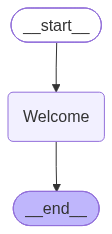

In [346]:
final_graph

In [347]:
res = final_graph.invoke({"messages": "Hello Naveen Singh"})

In [348]:
res

{'message': ' Good Morning!!', 'isPassed': True}

#### 2.2 Multi Node Graph

In [349]:
from random import randint

class ReviewState(BaseModel):
    text: str = ""
    score: int = 0
    comments: str = ""

def score(state:ReviewState) -> ReviewState:
    state.score = randint(1, 10)
    return state

def commenter(state:ReviewState) -> ReviewState:
    if state.score > 5:
        state.comments = "Well Done"
    else:
        state.comments = "Need improvement"
    return  state
graph = StateGraph(ReviewState)
graph.add_node("score", score)
graph.add_node("commenter", commenter)

graph.add_edge(START, "score")
graph.add_edge("score", "commenter")
graph.add_edge("commenter", END)

final_graph_2 = graph.compile()

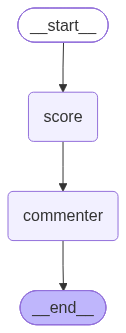

In [350]:
final_graph_2

In [351]:
res_2 = final_graph_2.invoke({})

In [352]:
res_2

{'text': '', 'score': 3, 'comments': 'Need improvement'}

#### 3. Add_messages reducer - for chat history

In [353]:
from langgraph.graph.message import add_messages
from langchain_core.messages import HumanMessage, AIMessage
from typing import Annotated

class ChatState(BaseModel):
    messages: Annotated[list, add_messages] = []

def Chat_bot(state:ChatState):
    print(state.messages)

graph = StateGraph(ChatState)

graph.add_node("chat_bot", Chat_bot)
graph.add_edge(START, "chat_bot")
graph.add_edge("chat_bot", END)

final_graph_3 = graph.compile()

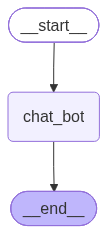

In [354]:
final_graph_3

In [355]:
# res_3 = final_graph_3.invoke({"messages": [ {"role":"user", "content": "Hello, how are u??"} ] })
# If we use HumanMessage the also the result will be same.
# Need to import HumanMessages, AIMessages
# from langchain_core.messages import HumanMessage, AIMessage -> Like this
res_3 = final_graph_3.invoke({"messages": [HumanMessage(content = "hello Laltu Ji")]})

[HumanMessage(content='hello Laltu Ji', additional_kwargs={}, response_metadata={}, id='9b478e70-52d0-4840-a6e0-1e0af98915cd')]


#### 3.1 Create Custome Reducers

In [356]:
from langgraph.graph.message  import add_messages
from langchain_core.messages import HumanMessage, AIMessage
from typing import Annotated

def custom_reducer(existing: list, new:list):
    all_msg = existing + new
    return all_msg[-2:]

def isPositive(existing: int, new:int):
    if new <0:
        return 0
    return new

class ChatState(BaseModel):
    messages: Annotated[list, custom_reducer] = []
    count: Annotated[int, isPositive] = 0

def chat_bot(state:ChatState):
    state.messages = [llm.invoke(state.messages)]
    state.count = -10
    return state

graph = StateGraph(ChatState)

graph.add_node("chat_bot", chat_bot)
graph.add_edge(START, "chat_bot")
graph.add_edge("chat_bot", END)

final_graph = graph.compile()

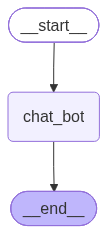

In [357]:
final_graph

In [358]:
res = final_graph.invoke({"messages": [HumanMessage(content = "Hello, How are you?")]})

In [359]:
res

{'messages': [HumanMessage(content='Hello, How are you?', additional_kwargs={}, response_metadata={}),
  AIMessage(content="Hello! I'm doing great, thanks for asking. How can I help you today?", additional_kwargs={'reasoning_content': 'We need to respond as ChatGPT. The system message says we are ChatGPT, no special instructions beyond that. The developer message is empty, so no extra constraints. The user says "Hello, How are you?" We should respond politely, maybe ask how they are, etc.'}, response_metadata={'token_usage': {'completion_tokens': 84, 'prompt_tokens': 77, 'total_tokens': 161, 'completion_time': 0.176372228, 'completion_tokens_details': {'reasoning_tokens': 58}, 'prompt_time': 0.037534691, 'prompt_tokens_details': None, 'queue_time': 0.425151759, 'total_time': 0.213906919}, 'model_name': 'openai/gpt-oss-120b', 'system_fingerprint': 'fp_8655ddce88', 'service_tier': 'on_demand', 'finish_reason': 'stop', 'logprobs': None, 'model_provider': 'groq'}, id='lc_run--01a17758-b588

#### 4. Conditional Routing

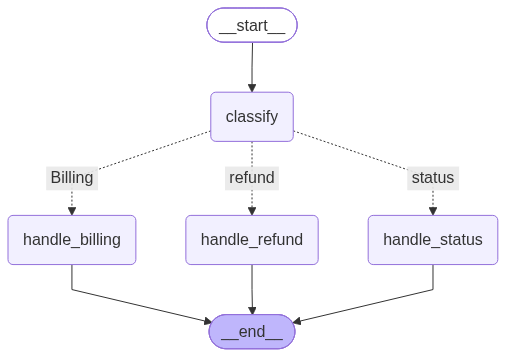

In [360]:
from langgraph.graph import StateGraph, START, END
from pydantic import BaseModel
from typing import Literal

class TicketState(BaseModel):
    issue:str = ""
    category:str = ""
    response:str = ""

def classify(state:TicketState)-> TicketState:
    issue = state.issue.lower()
    if "payment" in issue or "amount" in issue:
        state.category ="billing"

    elif "refund" in issue or "cancel" in issue:
        state.category = "refund"

    else:
        state.category = "status"
    return state

def handle_billing(state:TicketState)-> TicketState:
    print('Billing Related Issue')
    state.response = f"Issue Resolved for {state.category}"
    return state

def handle_refund(state:TicketState) -> TicketState:
    print('Refund Related Issue')
    state.response = f"Issue Resolved for {state.category}"
    return state

def handle_status(state:TicketState)-> TicketState:
    print("Status Related Issue")
    state.response = f"Issue resolved for {state.category}"
    return state

def router_logic(state:TicketState) -> Literal["billing", "refund", "status"]:
    return state.category

graph = StateGraph(TicketState)
graph.add_node("classify", classify)
graph.add_node("handle_billing", handle_billing)
graph.add_node("handle_refund", handle_refund)
graph.add_node("handle_status", handle_status)

graph.add_edge(START, "classify")
graph.add_conditional_edges("classify", router_logic,
                            {"Billing": "handle_billing",
                             "status": "handle_status",
                             "refund": "handle_refund"}
                             )
graph.add_edge("handle_billing", END)
graph.add_edge("handle_refund", END)
graph.add_edge("handle_status", END)

final_graph = graph.compile()
final_graph


In [361]:
res_4 = final_graph.invoke({"issue": "I am waiting for my refund"})

Refund Related Issue


In [362]:
res_4

{'issue': 'I am waiting for my refund',
 'category': 'refund',
 'response': 'Issue Resolved for refund'}

#### 5. Memomry Checkpointer

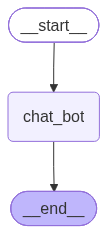

In [363]:
from langgraph.graph import StateGraph, START, END
from pydantic import BaseModel
from typing import Annotated
from langgraph.checkpoint.memory import InMemorySaver

class ChatState(BaseModel):
    messages: Annotated[list, add_messages] = []
    # count: int = 0

def chat_bot(state:ChatState):
    state.messages = [llm.invoke(state.messages)]
    # state.count = -10
    return state

graph =StateGraph(ChatState)

graph.add_node("chat_bot",chat_bot)
graph.add_edge(START, "chat_bot")
graph.add_edge("chat_bot", END)
memory = InMemorySaver()
final_graph_5 = graph.compile(checkpointer=memory)

final_graph_5

    

In [364]:
res_5 = final_graph_5.invoke({"messages": [ HumanMessage(content="What is his age??")]},
                             {"configurable": {"thread_id":"asd1"}})
ans = res_5["messages"][-1].content
print(ans)

I’m not sure who you’re referring to. Could you provide a bit more context or tell me who “he” is? That’ll help me give you an accurate answer.


In [365]:
%pip install langgraph-checkpoint-sqlite


[notice] A new release of pip is available: 25.0.1 -> 26.2.2
[notice] To update, run: pip install --upgrade pip

[notice] A new release of pip is available: 25.0.1 -> 26.2.2
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.
Note: you may need to restart the kernel to use updated packages.


In [366]:
import sqlite3
from langgraph.checkpoint.sqlite import SqliteSaver

connection = sqlite3.connect("db.sqlite3", check_same_thread=False)
sql_memory = SqliteSaver(connection)
sql_memory.setup()

In [367]:
sqlite_graph = graph.compile(checkpointer=sql_memory)

In [368]:
res_6 = sqlite_graph.invoke(
    {"messages": 
     [HumanMessage(content= "What is his age??")]
     }, 
     {"configurable":{"thread_id":"asd2"}}
)

ans_1 = res_6["messages"][-1].content
print(ans_1)

Amit Shah was born on **22 October 1964**.  
Given today’s date (24 October 2026), he is **62 years old**—he just turned 62 two days ago.


In [369]:
import sqlite3

conn = sqlite3.connect("db.sqlite3")
cur = conn.cursor()
cur.execute("SELECT name, sql FROM sqlite_master WHERE type='table';")
for name, sql in cur.fetchall():
    print(f"--- {name} ---")
    print(sql)
cur.execute("SELECT thread_id, checkpoint_id FROM checkpoints;")
print(cur.fetchall())
conn.close()

--- checkpoints ---
CREATE TABLE checkpoints (
                thread_id TEXT NOT NULL,
                checkpoint_ns TEXT NOT NULL DEFAULT '',
                checkpoint_id TEXT NOT NULL,
                parent_checkpoint_id TEXT,
                type TEXT,
                checkpoint BLOB,
                metadata BLOB,
                PRIMARY KEY (thread_id, checkpoint_ns, checkpoint_id)
            )
--- writes ---
CREATE TABLE writes (
                thread_id TEXT NOT NULL,
                checkpoint_ns TEXT NOT NULL DEFAULT '',
                checkpoint_id TEXT NOT NULL,
                task_id TEXT NOT NULL,
                task_path TEXT NOT NULL DEFAULT '',
                idx INTEGER NOT NULL,
                channel TEXT NOT NULL,
                type TEXT,
                value BLOB,
                PRIMARY KEY (thread_id, checkpoint_ns, checkpoint_id, task_id, idx)
            )
[('asd2', '1f1cf9a1-8b34-6d98-bfff-c084889ec8d6'), ('asd2', '1f1cf9a1-8b37-6b24-8000-d71153a3

In [370]:
import os, sqlite3

DB_PATH = "/Users/laltusingh/Desktop/LangGraph-Course/db.sqlite3"
print("Kernel cwd:", os.getcwd())
print("DB exists:", os.path.exists(DB_PATH))

conn = sqlite3.connect(DB_PATH)
cur = conn.cursor()
print("checkpoints rows:", cur.execute("SELECT COUNT(*) FROM checkpoints;").fetchone()[0])
print("writes rows:", cur.execute("SELECT COUNT(*) FROM writes;").fetchone()[0])
conn.close()

Kernel cwd: /Users/laltusingh/Desktop/LangGraph-Course
DB exists: True
checkpoints rows: 91
writes rows: 101


#### 6. Agent and Tools - ToolNodes

In [371]:
from langchain.tools import tool

@tool
def weather_tool(city:str) -> str:
    """
        Get the real time wheather details for any city.
        Args:
        City- city name for the weather details
    """
    ### Real weather API call
    data= {
        "bhopal": "32",
        "delhi": "38",
        "mumbai": "36"
    }

    return data.get(city.lower().strip(), "City not found")
@tool
def calculate(expression:str):
    """
        Execute the math equations: Ex. '4 * 4 -4'
    """
    try:
        return eval(expression)
    except:
        return "Please provide the correct expression"

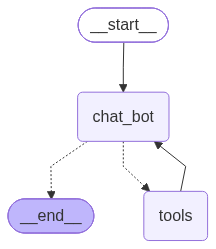

In [372]:
from typing import Annotated
from pydantic import BaseModel
from langchain_core.messages import HumanMessage
from langgraph.graph.message import add_messages
from langgraph.graph import StateGraph, START, END
from langgraph.prebuilt import tools_condition, ToolNode

class AgentState(BaseModel):
    messages: Annotated[list, add_messages]

tools = [weather_tool, calculate]
llm_with_tools = llm.bind_tools(tools)

def chat_bot(state:AgentState):
    res = llm_with_tools.invoke(state.messages)
    # state.messages = [res]
    #Problem: This replaces the entire message history with the latest AI response. 
    # That can remove the original user message and previous tool results, 
    # which the agent needs for a proper conversation.
    # With LangGraph's add_messages reducer, the preferred approach is to 
    # return only the newly generated message.
    return {"messages":[res]}

tool_node = ToolNode(tools)

graph  = StateGraph(AgentState)
graph.add_node("chat_bot", chat_bot)
graph.add_node("tools", tool_node)

graph.add_edge(START, "chat_bot")
graph.add_conditional_edges("chat_bot", tools_condition)
graph.add_edge("tools", "chat_bot")
# graph.add_edge("chat_bot", END)
# Problem: tools_condition already decides where the graph should go:
# - If the LLM requests a tool, route to "tools".
# - If the LLM doesn't request a tool, route to END.
# The conditional function expects the graph to have a 
# "tools" node and an END route. Adding an unconditional edge 
# from "chat_bot" to END is redundant and can create an unintended routing path.

final_graph_6 = graph.compile(checkpointer= sql_memory)

final_graph_6

In [373]:
res = final_graph_6.invoke(
    {"messages":
        [HumanMessage(content="What is the temperature in Mumbai??")]
        },
     {"configurable":{"thread_id":"asd3"}}
    )

ans_2 = res['messages'][-1].content

In [374]:
res["messages"][-1].content

'I’m sorry—I’m still unable to pull a live weather reading for Mumbai right now. The most recent temperature I have on file for the city is **about\u202f34\u202f°C**.\n\nIf you need the very latest figure, you can check a real‑time weather service such as Weather.com, AccuWeather, or the India Meteorological Department. Let me know if you’d like a short‑term forecast, humidity, or any other weather details for Mumbai!'

In [375]:
test = llm_with_tools.invoke([
    HumanMessage(content="What is the temperature in Mumbai?")
])

print("Content:", test.content)
print("Tool calls:", test.tool_calls)

Content: 
Tool calls: [{'name': 'weather_tool', 'args': {'city': 'Mumbai'}, 'id': 'fc_036eb74d-b863-4357-bd83-f0400cec085d', 'type': 'tool_call'}]
